# ChessGPT — v2: MLP with a context window and embeddings

## Where we are
| Version | Model | Bits/char | Legal move rate |
|---|---|---|---|
| — | Frequency baseline (random real move, no context) | — | 11.2% |
| v1 | Bigram (1 character of context) | 2.430 | 10.2% |

The bigram learned the *alphabet* of SAN, but with one character of context it could not even write well-formed moves (`Bxdxe6`, `Kcxf5`), and it did not beat the baseline.

## What changes in v2
The model now sees the last **16 characters**, about the last 3–4 moves, through the architecture of Bengio et al. (2003), *A Neural Probabilistic Language Model*:

1. each character is mapped to a learned vector, its **embedding**;
2. the 16 embeddings are concatenated and passed through an **MLP**;
3. a softmax gives the distribution of the next character.

## What we measure
Everything from v1, on **exactly the same** data split and the same 1,000 test positions:
- validation **bits per character**;
- **legal move rate**, overall and by game phase;
- **self-play**: legal plies before the first illegal move.

New in v2:
- **well-formed rate**: the fraction of generated moves that are syntactically valid SAN, legal or not. This separates "writes something that looks like a move" from "writes a legal move";
- a **temperature** comparison;
- a picture of the learned **embedding space**.

## Requirements
Run `chessgpt_v1.ipynb` first: v2 loads the cleaned games from `data`.
Training takes a few minutes on the Apple GPU.

In [1]:
# --- CORE LIBRARIES ---

# PyTorch: tensors, automatic gradients, neural networks.
import torch

# Neural network layers.
import torch.nn as nn

# Functional operations: softmax, cross-entropy.
import torch.nn.functional as F

# Numerical computing.
import numpy as np

# Plotting.
import matplotlib.pyplot as plt

# python-chess: rules, legal moves, SAN parsing.
import chess

# SVG drawings of chess boards.
import chess.svg

# Display SVG images in the notebook.
from IPython.display import SVG, display

# Counting occurrences.
from collections import Counter

# File and folder paths.
from pathlib import Path

# Regular expressions: syntactic check of SAN moves.
import re

# Measure execution time.
import time

# Python's random module.
import random

# Read and write the shared results file.
import json

# Independent copies of objects (a CPU copy of the model for fast sampling).
import copy

In [2]:
# --- DEVICE AND REPRODUCIBILITY ---

# Fastest device available: NVIDIA GPU, Apple Silicon GPU, or CPU.
if torch.cuda.is_available():

    # NVIDIA GPU.
    device = torch.device("cuda")

elif torch.backends.mps.is_available():

    # Apple Silicon GPU.
    device = torch.device("mps")

else:

    # CPU.
    device = torch.device("cpu")

# Seed for PyTorch.
torch.manual_seed(42)

# Seed for Python's random module.
random.seed(42)

# Seed for NumPy.
np.random.seed(42)

# Print the device.
print("Device:", device)

Device: mps


## Step 1 — Load the data and rebuild exactly the same split as v1

To compare versions fairly, everything that is not the model must be **identical**:
- the cleaned games saved by v1;
- the vocabulary: the same characters in the same sorted order, so the same indices;
- the train / validation / test split: the same shuffle with seed 42;
- the 1,000 test positions: the same generator with seed 123.

The check: the vocabulary must again have **29 characters**, and the split must contain 104,066 / 5,781 / 5,781 games.

In [3]:
# --- LOAD THE CLEANED GAMES FROM v1 ---

# Folder with the chess data.
DATA_DIR = Path("data/lichess")

# File written by v1: one game per line.
GAMES_PATH = DATA_DIR / "games_2013-01.txt"

# Stop with a clear message if v1 has not been run.
assert GAMES_PATH.exists(), "Run chessgpt_v1.ipynb first."

# One game per line.
games = GAMES_PATH.read_text(encoding="utf-8").split("\n")

# --- SAME VOCABULARY AS v1 ---

# Start/end-of-game token.
SEP = ";"

# Same sorted set of characters.
chars = sorted(set("".join(games)) | {SEP})

# Vocabulary size (expected 29).
V = len(chars)

# Character -> index.
stoi = {c: i for i, c in enumerate(chars)}

# Index -> character.
itos = {i: c for c, i in stoi.items()}

# --- SAME SPLIT AS v1 ---

# Copy of the games.
shuffled = games[:]

# Same shuffle as v1 (seed 42).
random.Random(42).shuffle(shuffled)

# 5% validation, 5% test.
n_val = n_test = len(shuffled) // 20

# Validation games.
val_games = shuffled[:n_val]

# Test games.
test_games = shuffled[n_val:n_val + n_test]

# Training games.
train_games = shuffled[n_val + n_test:]

# Checks.
print(f"Vocabulary: {V} characters | Train: {len(train_games):,} | Validation: {len(val_games):,} | Test: {len(test_games):,}")

# --- FAST ENCODING (same lookup table as v1) ---

# Byte value -> vocabulary index.
lookup = np.full(256, -1, dtype=np.int64)

# Fill the table.
for c, i in stoi.items():

    # One entry per character.
    lookup[ord(c)] = i


# Encode a string into a NumPy array of indices.
def encode(text):
    """String -> int64 array of vocabulary indices (all characters must be in the vocabulary)."""

    # Raw bytes translated through the lookup table.
    ids = lookup[np.frombuffer(text.encode("ascii"), dtype=np.uint8)]

    # Safety check.
    assert (ids >= 0).all()

    # Return the indices.
    return ids

Vocabulary: 29 characters | Train: 104,066 | Validation: 5,781 | Test: 5,781


## Step 2 — Training examples: (16 characters of context → next character)

### The context window
For every character $c_t$ of every game, the input is the **16 previous characters** $c_{t-16}, \dots, c_{t-1}$ and the target is $c_t$:

$$
P(c_t \mid c_1, \dots, c_{t-1}) \approx P(c_t \mid c_{t-16}, \dots, c_{t-1})
$$

With about 4 characters per ply, 16 characters cover roughly the **last 3–4 moves**: enough to know which move we are in the middle of, and the opponent's last reply.

### Padding at the start of a game
At the beginning of a game there are fewer than 16 previous characters. We **left-pad** with `;` (the start token), so the model always knows "the game has just started":

```
target 'e' (first move)  ← context ;;;;;;;;;;;;;;;;
target '4'               ← context ;;;;;;;;;;;;;;;e
target ' '               ← context ;;;;;;;;;;;;;;e4
```

The same padding is used when the model generates moves, so training and generation see exactly the same kind of inputs.

### An efficient implementation
Materialising every 16-character window would take $31.8\text{M} \times 16$ integers (about 4 GB). Instead:
1. we build one long padded stream: `[16 × ;] game₁ [16 × ;] game₂ … ;`;
2. we store only the **positions of the targets** in that stream;
3. at training time, the 16 characters before each sampled position are gathered with one indexing operation on the GPU.

The targets of each game are all its characters **plus** the `;` that follows it, so the model also learns when a game ends. These are exactly the same targets as in the v1 bigram evaluation, so bits per character are directly comparable.

In [4]:
# --- CONTEXT LENGTH ---

# Number of previous characters the model sees.
BLOCK = 16


# Build the padded stream and the positions of all targets for a list of games.
def build_stream(game_list):
    """Return (stream of indices, positions of the targets in the stream)."""

    # One long string: each game preceded by BLOCK separators; one final separator ends the last game.
    text = "".join(SEP * BLOCK + g for g in game_list) + SEP

    # Encode it.
    stream = encode(text)

    # Length of every game in characters.
    lengths = np.array([len(g) for g in game_list])

    # Start of every game's padding block: cumulative sum of (padding + game) lengths, shifted by one game.
    pad_starts = np.concatenate([[0], np.cumsum(BLOCK + lengths)[:-1]])

    # First character of every game.
    game_starts = pad_starts + BLOCK

    # Targets of each game: its characters and the separator right after it (length + 1 positions).
    targets = np.concatenate([np.arange(s, s + l + 1) for s, l in zip(game_starts, lengths)])

    # Return both arrays.
    return stream, targets


# Training stream and targets.
train_stream, train_targets = build_stream(train_games)

# Validation stream and targets.
val_stream, val_targets = build_stream(val_games)

# Sizes.
print(f"Training targets: {len(train_targets):,} | Validation targets: {len(val_targets):,}")

# Move everything to the device as tensors.
train_stream_t = torch.tensor(train_stream, device=device)

# Training target positions.
train_targets_t = torch.tensor(train_targets, device=device)

# Validation stream.
val_stream_t = torch.tensor(val_stream, device=device)

# Validation target positions.
val_targets_t = torch.tensor(val_targets, device=device)

# Offsets -BLOCK, ..., -1: added to a target position, they give the positions of its context.
offsets = torch.arange(-BLOCK, 0, device=device)


# Gather a batch of (contexts, targets) from a stream, given target positions.
def get_batch(stream_t, positions):
    """positions: 1-D tensor of target positions. Returns contexts (B, BLOCK) and targets (B,)."""

    # positions[:, None] + offsets[None, :] is a (B, BLOCK) matrix of context positions (broadcasting).
    contexts = stream_t[positions[:, None] + offsets[None, :]]

    # The characters to predict.
    targets = stream_t[positions]

    # Return both.
    return contexts, targets


# Show three examples from the training data.
ctx, tgt = get_batch(train_stream_t, train_targets_t[:3])

# Decode and print them.
for c, t in zip(ctx.tolist(), tgt.tolist()):

    # Context characters joined into a string, then the target character.
    print(f"context '{''.join(itos[i] for i in c)}' -> target '{itos[t]}'")

Training targets: 30,128,101 | Validation targets: 1,659,961
context ';;;;;;;;;;;;;;;;' -> target 'd'
context ';;;;;;;;;;;;;;;d' -> target '4'
context ';;;;;;;;;;;;;;d4' -> target ' '


## Step 3 — The model: embeddings + MLP (Bengio et al., 2003)

### Embeddings
Each character $c$ is mapped to a learned vector $e_c \in \mathbb{R}^{d}$, a row of the **embedding matrix** $E \in \mathbb{R}^{|\mathcal{V}| \times d}$:

$$
e_c = E_{c,:}
$$

It is the same "select a row" operation as the bigram's $W_{a,:}$. The difference is that the row is now a compact **description** of the character, $d = 24$ numbers, learned by backpropagation, instead of the final logits.
Characters that play similar roles (the files `a`–`h`, the ranks `1`–`8`, the pieces `N B R Q K`) should end up with similar vectors.

### The network
The 16 embeddings are concatenated into one vector and passed through an MLP with two hidden layers:

$$
\begin{aligned}
x &= [\,e_{c_{t-16}};\; e_{c_{t-15}};\; \dots;\; e_{c_{t-1}}\,] \in \mathbb{R}^{16 d} \\
h_1 &= \operatorname{ReLU}(W_1 x + b_1), \quad h_2 = \operatorname{ReLU}(W_2 h_1 + b_2) \\
z &= W_3 h_2 + b_3, \qquad P(c_t \mid \text{context}) = \operatorname{softmax}(z)
\end{aligned}
$$

Concatenating keeps the **order**: the network knows which character is the most recent one.

### Parameters
| Layer | Shape | Parameters |
|---|---|---|
| Embedding $E$ | $29 \times 24$ | 696 |
| $W_1, b_1$ | $384 \to 512$ | 197,120 |
| $W_2, b_2$ | $512 \to 512$ | 262,656 |
| $W_3, b_3$ | $512 \to 29$ | 14,877 |
| **Total** | | **475,349** |

### Loss
Cross-entropy, i.e. the average NLL of the true next character, exactly as before.

In [5]:
# --- THE MODEL ---

# Embedding size: each character becomes a vector of 24 learned numbers.
EMB_DIM = 24

# Width of the two hidden layers.
HIDDEN = 512


# Bengio-style character MLP.
class CharMLP(nn.Module):

    # Declare the layers.
    def __init__(self, vocab_size, block, emb_dim, hidden):

        # Initialise the parent class.
        super().__init__()

        # Embedding table: vocab_size rows, emb_dim columns; row c is the vector of character c.
        self.embedding = nn.Embedding(vocab_size, emb_dim)

        # The MLP that turns the concatenated context into logits.
        self.mlp = nn.Sequential(

            # Concatenated embeddings (block * emb_dim) -> first hidden layer.
            nn.Linear(block * emb_dim, hidden),

            # Non-linearity.
            nn.ReLU(),

            # Second hidden layer.
            nn.Linear(hidden, hidden),

            # Non-linearity.
            nn.ReLU(),

            # Output layer: one logit per possible next character.
            nn.Linear(hidden, vocab_size),
        )

    # Forward pass.
    def forward(self, contexts):
        """contexts: (B, block) tensor of character indices. Returns logits (B, vocab_size)."""

        # Look up the embeddings: (B, block) -> (B, block, emb_dim).
        emb = self.embedding(contexts)

        # Concatenate the block embeddings of each example: (B, block, emb_dim) -> (B, block * emb_dim).
        x = emb.flatten(start_dim=1)

        # Logits.
        return self.mlp(x)


# Create the model on the device.
model = CharMLP(V, BLOCK, EMB_DIM, HIDDEN).to(device)

# Count the parameters: expected 475,349.
n_params = sum(p.numel() for p in model.parameters())

# Print the structure and the count.
print(model)

# Total.
print(f"Parameters: {n_params:,}")

CharMLP(
  (embedding): Embedding(29, 24)
  (mlp): Sequential(
    (0): Linear(in_features=384, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=29, bias=True)
  )
)
Parameters: 475,349


## Step 4 — Training

| Setting | Value |
|---|---|
| Optimizer | **AdamW** (Adam + weight decay $\lambda = 0.01$) |
| Learning rate | $10^{-3}$, cosine decay to $5 \cdot 10^{-5}$ |
| Batch | 1,024 random (context, target) pairs |
| Steps | 30,000, i.e. about 31 million examples, roughly one pass over the training data |

**AdamW** adds a small pull of every weight towards zero at each step (*decoupled weight decay*):

$$
\theta \leftarrow \theta - \eta_t \left( \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon} + \lambda\, \theta \right)
$$

This keeps the weights small, a mild form of regularisation.

Every 1,000 steps we measure the loss on a fixed sample of 50,000 validation targets, to follow training without slowing it down. At the end we compute the exact validation NLL on all 1.7 million validation targets.

**A detail about speed:** calling `loss.item()` copies a number from the GPU to the CPU and forces the GPU to finish all pending work. Doing it at every step slows training down. We accumulate the loss on the GPU and read it only every 1,000 steps.

step   5000 | train 1.696 bpc | val 1.688 bpc | 32s
step  10000 | train 1.630 bpc | val 1.632 bpc | 64s
step  15000 | train 1.598 bpc | val 1.599 bpc | 97s
step  20000 | train 1.571 bpc | val 1.576 bpc | 130s
step  25000 | train 1.555 bpc | val 1.562 bpc | 168s
step  30000 | train 1.549 bpc | val 1.556 bpc | 205s

Validation: NLL 1.080 nats | perplexity 2.94 | 1.558 bits/char   (v1 bigram: 2.430)


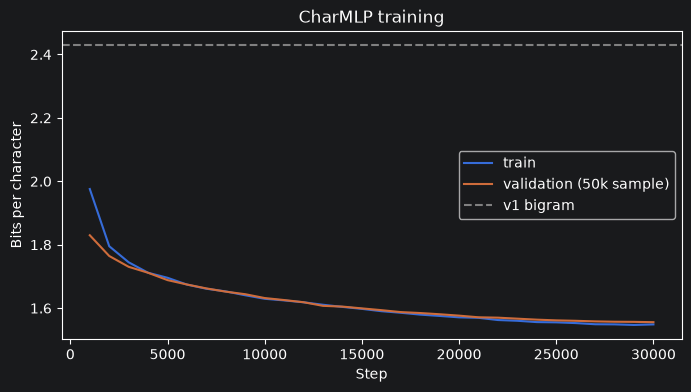

In [6]:
# --- TRAINING SETTINGS ---

# Number of optimisation steps.
STEPS = 30_000

# Examples per step.
BATCH = 1024

# Initial learning rate.
LR = 1e-3

# Evaluate every EVAL_EVERY steps.
EVAL_EVERY = 1000

# AdamW: Adam with decoupled weight decay.
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)

# Cosine schedule over all the steps, down to LR / 20.
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=STEPS, eta_min=LR / 20)

# Fixed random sample of 50,000 validation targets for the periodic evaluation (NumPy generator, seed 0).
val_sample = val_targets_t[torch.tensor(np.random.default_rng(0).choice(len(val_targets), 50_000, replace=False), device=device)]


# Average NLL (nats per character) on a set of target positions, in batches.
@torch.no_grad()
def eval_nll(stream_t, positions, batch=8192):
    """Exact average cross-entropy over all the given target positions."""

    # Evaluation mode (no effect for this model, but good practice).
    model.eval()

    # Sum of the losses.
    total = 0.0

    # Go through the positions in chunks.
    for i in range(0, len(positions), batch):

        # Contexts and targets of this chunk.
        ctx, tgt = get_batch(stream_t, positions[i:i + batch])

        # Sum (not mean) of the cross-entropies of the chunk.
        total += F.cross_entropy(model(ctx), tgt, reduction="sum").item()

    # Back to training mode.
    model.train()

    # Average over all positions.
    return total / len(positions)


# History for the plot.
history = {"step": [], "train": [], "val": []}

# Running sum of the training losses, kept on the GPU.
running = torch.zeros((), device=device)

# Start time.
start = time.perf_counter()

# Training mode.
model.train()

# Training loop.
for step in range(1, STEPS + 1):

    # Random target positions in the training stream.
    pos = train_targets_t[torch.randint(0, len(train_targets_t), (BATCH,), device=device)]

    # Their contexts and targets.
    ctx, tgt = get_batch(train_stream_t, pos)

    # Forward pass and cross-entropy.
    loss = F.cross_entropy(model(ctx), tgt)

    # Reset gradients.
    optimizer.zero_grad()

    # Backpropagation.
    loss.backward()

    # Update the parameters.
    optimizer.step()

    # Update the learning rate.
    scheduler.step()

    # Accumulate the loss without leaving the GPU (detach: no gradient history).
    running += loss.detach()

    # Periodic evaluation.
    if step % EVAL_EVERY == 0:

        # Average training loss over the last EVAL_EVERY steps (.item() reads it once).
        train_loss = running.item() / EVAL_EVERY

        # Reset the running sum.
        running.zero_()

        # Validation loss on the fixed sample.
        val_loss = eval_nll(val_stream_t, val_sample)

        # Store.
        history["step"].append(step)

        # Training loss.
        history["train"].append(train_loss)

        # Validation loss.
        history["val"].append(val_loss)

        # Print progress every 5,000 steps; bits per char = nats / ln 2.
        if step % 5000 == 0:

            # Progress line.
            print(f"step {step:6d} | train {train_loss / np.log(2):.3f} bpc | val {val_loss / np.log(2):.3f} bpc | {time.perf_counter() - start:.0f}s")

# --- EXACT VALIDATION NLL ON ALL TARGETS ---

# Average NLL in nats.
nll_mlp = eval_nll(val_stream_t, val_targets_t)

# Bits per character.
bpc_mlp = nll_mlp / np.log(2)

# Report.
print(f"\nValidation: NLL {nll_mlp:.3f} nats | perplexity {np.exp(nll_mlp):.2f} | {bpc_mlp:.3f} bits/char   (v1 bigram: 2.430)")

# --- LEARNING CURVES ---

# One panel.
fig, ax = plt.subplots(figsize=(8, 4))

# Training curve in bits per character.
ax.plot(history["step"], np.array(history["train"]) / np.log(2), label="train")

# Validation curve.
ax.plot(history["step"], np.array(history["val"]) / np.log(2), label="validation (50k sample)")

# The bigram result for reference.
ax.axhline(2.430, linestyle="--", color="gray", label="v1 bigram")

# Axis labels.
ax.set_xlabel("Step")

# y-axis label.
ax.set_ylabel("Bits per character")

# Title.
ax.set_title("CharMLP training")

# Legend.
ax.legend()

# Render the figure.
plt.show()

## Step 5 — What did the embeddings learn?

Each character is now a point in a 24-dimensional space. To look at it, we project the 29 embeddings onto their **first two principal components** (PCA): the two directions along which the points vary the most.

With the centred embedding matrix $\tilde{E} = E - \bar{e}$, the singular value decomposition gives:

$$
\tilde{E} = U \Sigma V^\top,
\qquad
\text{2-D coordinates} = \tilde{E}\, V_{:, 1:2},
\qquad
\text{explained variance}_k = \frac{\sigma_k^2}{\sum_j \sigma_j^2}
$$

**Nobody told the model** which characters are files, ranks or pieces. If they form separate groups in the picture, the network has discovered these categories by itself, only because they appear in similar positions in the text.

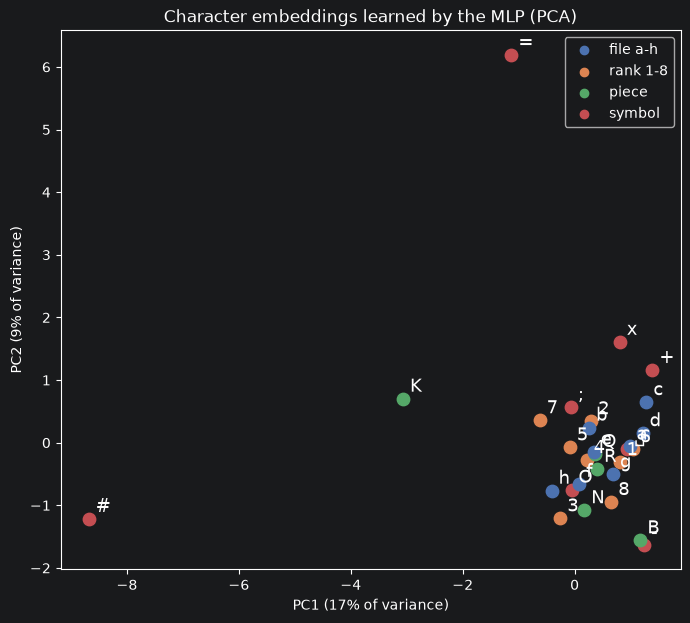

In [7]:
# --- PCA OF THE EMBEDDINGS ---

# Embedding matrix (29 x 24) as a NumPy array.
E = model.embedding.weight.detach().cpu().numpy()

# Centre it: subtract the mean vector.
E_centered = E - E.mean(axis=0)

# Singular value decomposition; full_matrices=False returns the compact form.
U, S, Vt = np.linalg.svd(E_centered, full_matrices=False)

# Coordinates on the first two principal directions (rows of Vt).
coords = E_centered @ Vt[:2].T

# Fraction of the variance explained by each of the two components.
explained = S[:2] ** 2 / (S ** 2).sum()


# Group of a character, for the colours.
def char_group(c):
    """Return a category name for a vocabulary character."""

    # Files a-h.
    if c in "abcdefgh":

        # Category.
        return "file a-h"

    # Ranks 1-8.
    if c in "12345678":

        # Category.
        return "rank 1-8"

    # Pieces.
    if c in "KQRBN":

        # Category.
        return "piece"

    # Everything else: x, +, #, =, -, O, space, ;.
    return "symbol"


# One colour per group.
GROUP_COLORS = {"file a-h": "#4C72B0", "rank 1-8": "#DD8452", "piece": "#55A868", "symbol": "#C44E52"}

# Square figure.
fig, ax = plt.subplots(figsize=(8, 7))

# One point and one label per character.
for i, c in enumerate(chars):

    # Group of the character.
    group = char_group(c)

    # The point.
    ax.scatter(coords[i, 0], coords[i, 1], color=GROUP_COLORS[group], s=80)

    # The label next to it; the space is shown as "␣".
    ax.annotate("␣" if c == " " else c, coords[i], fontsize=13, xytext=(5, 5), textcoords="offset points")

# Legend: one invisible point per group, just to create the legend entries.
for group, color in GROUP_COLORS.items():

    # Empty scatter with a label.
    ax.scatter([], [], color=color, label=group)

# Legend.
ax.legend()

# Axis labels with the explained variance.
ax.set_xlabel(f"PC1 ({explained[0]:.0%} of variance)")

# y-axis label.
ax.set_ylabel(f"PC2 ({explained[1]:.0%} of variance)")

# Title.
ax.set_title("Character embeddings learned by the MLP (PCA)")

# Render the figure.
plt.show()

## Step 6 — The evaluation harness (same as v1, plus well-formedness)

Exactly the same evaluation as v1: the same 1,000 test positions (seed 123), the same legality check, the same self-play.

### Sampling on the CPU
During evaluation the model is called **once per character**, on a single context. For such tiny inputs, sending data to the GPU and back costs more than the computation itself. We therefore copy the trained model to the CPU for sampling.

### New metric: well-formed moves
A move can be **well-formed** but illegal (`Nf3` when no knight can reach f3), or not even well-formed (`Bxdxe6`). The well-formed check is a regular expression for SAN:

```
O-O | O-O-O                              castling
[KQRBN] [a-h]? [1-8]? x? [a-h][1-8]      piece move, optional disambiguation and capture
[a-h] (x[a-h])? [1-8] (=[QRBN])?         pawn move, optional capture and promotion
… followed by an optional + or #
```

The ratio *legal / well-formed* tells us how often the model's syntactically correct moves also fit the position.

### The bigram again, for a side-by-side comparison
The v1 bigram takes a second to rebuild by counting, so we include it in every chart.

In [8]:
# --- REBUILD THE v1 BIGRAM (for the comparison) ---

# Training text exactly as in v1.
bigram_ids = encode(SEP + SEP.join(train_games) + SEP)

# Pair counts with bincount, as in v1.
counts = np.bincount(bigram_ids[:-1] * V + bigram_ids[1:], minlength=V * V).reshape(V, V)

# Laplace-smoothed probabilities.
P_count = (counts + 1.0) / (counts + 1.0).sum(axis=1, keepdims=True)


# Bigram next-character distribution (only the last character matters).
def bigram_next_char_probs(context):
    """Row of the bigram table for the last character of the context."""

    # Probability vector.
    return P_count[context[-1]]


# --- MLP NEXT-CHARACTER DISTRIBUTION (on the CPU) ---

# Independent copy of the trained model on the CPU, in evaluation mode.
model_cpu = copy.deepcopy(model).to("cpu").eval()


# Same interface as the bigram: list of indices -> probabilities of the next character.
@torch.no_grad()
def mlp_next_char_probs(context):
    """Use the last BLOCK characters, left-padded with ';' at the start of a game."""

    # The last BLOCK characters of the context.
    ctx = context[-BLOCK:]

    # Left padding with the start token, exactly as in training.
    ctx = [stoi[SEP]] * (BLOCK - len(ctx)) + ctx

    # Logits for a batch containing this one context.
    logits = model_cpu(torch.tensor([ctx]))

    # Softmax, converted to float64 NumPy for precise sampling.
    return F.softmax(logits[0], dim=0).numpy().astype(np.float64)


# --- SAMPLING HELPERS (same as v1) ---

# Sample an index from a probability vector with temperature.
def sample_from(probs, temperature=1.0):
    """p^(1/T), renormalised, then one random draw."""

    # Sharpen or flatten.
    p = probs ** (1.0 / temperature)

    # Renormalise.
    p = p / p.sum()

    # Draw one index.
    return np.random.choice(len(p), p=p)


# Sample one move: characters until a space or the end-of-game token.
def sample_move(next_char_probs, context, temperature=1.0, max_len=10):
    """Return (move string, ended)."""

    # Copy of the context.
    context = list(context)

    # Characters of the move.
    move_chars = []

    # At most max_len characters.
    for _ in range(max_len):

        # Next character.
        nxt = sample_from(next_char_probs(context), temperature)

        # A space ends the move.
        if nxt == stoi[" "]:

            # Stop.
            break

        # The separator ends the game.
        if nxt == stoi[SEP]:

            # Return what we have and signal the end.
            return "".join(move_chars), True

        # Part of the move.
        move_chars.append(itos[nxt])

        # Becomes context.
        context.append(nxt)

    # Complete (or truncated) move.
    return "".join(move_chars), False


# Context for a game prefix.
def prefix_context(moves):
    """';' + moves separated by spaces + a trailing space if at least one move was played."""

    # The text.
    text = SEP + " ".join(moves) + (" " if moves else "")

    # Encoded character by character.
    return [stoi[c] for c in text]


# --- LEGALITY AND WELL-FORMEDNESS ---

# Is a SAN string a legal move on the board?
def is_legal(board, san):
    """True for a legal move; False for illegal, malformed or null moves."""

    # Try to parse.
    try:

        # bool(move) is False for the null move "--".
        return bool(board.parse_san(san))

    # Any parsing error.
    except ValueError:

        # Illegal.
        return False


# Regular expression for syntactically valid SAN (see the markdown above).
SAN_RE = re.compile(r"^(O-O(-O)?|[KQRBN][a-h]?[1-8]?x?[a-h][1-8]|[a-h](x[a-h])?[1-8](=[QRBN])?)[+#]?$")


# Is a string a well-formed SAN move (legal or not)?
def is_well_formed(san):
    """True if the string matches the SAN grammar."""

    # fullmatch-style check thanks to ^ and $ in the pattern.
    return SAN_RE.match(san) is not None


# --- THE SAME 1,000 TEST POSITIONS AS v1 ---

# Same generator and seed as v1.
pos_rng = random.Random(123)

# (moves so far, board) pairs.
test_positions = []

# Draw 1,000 positions.
while len(test_positions) < 1000:

    # A random test game.
    moves = pos_rng.choice(test_games).split()

    # A random cut point.
    k = pos_rng.randrange(len(moves))

    # Replay the prefix.
    board = chess.Board()

    # One move at a time.
    for m in moves[:k]:

        # Play it.
        board.push_san(m)

    # Store.
    test_positions.append((moves[:k], board))


# Evaluate a move proposer on the test positions.
def evaluate_legality(propose_move):
    """Return (legal rate, well-formed rate, list of (k, legal, san))."""

    # Details of every position.
    results = []

    # Go through the positions.
    for moves, board in test_positions:

        # Proposed move.
        san = propose_move(moves)

        # Store cut point, legality and the move itself.
        results.append((len(moves), is_legal(board, san), san))

    # Fraction of legal moves.
    legal_rate = np.mean([legal for _, legal, _ in results])

    # Fraction of well-formed moves.
    well_formed_rate = np.mean([is_well_formed(san) for _, _, san in results])

    # Return everything.
    return legal_rate, well_formed_rate, results


# Turn a character model into a move proposer.
def char_model_proposer(next_char_probs, temperature=1.0):
    """moves -> sampled SAN string."""

    # The proposer.
    def propose(moves):

        # Sample the next move.
        san, _ = sample_move(next_char_probs, prefix_context(moves), temperature)

        # Return it.
        return san

    # Return the function.
    return propose


# --- FREQUENCY BASELINE (same as v1) ---

# Move counts in the training games.
train_move_counts = Counter(m for g in train_games for m in g.split())

# Distinct moves.
baseline_moves = list(train_move_counts.keys())

# Their frequencies.
baseline_weights = list(train_move_counts.values())


# Random move with training frequencies, ignoring the position.
def frequency_baseline(moves):
    """One weighted random move."""

    # Weighted draw.
    return random.choices(baseline_moves, weights=baseline_weights, k=1)[0]


# --- SELF-PLAY (same as v1) ---

# The model plays both sides until the first illegal move.
def self_play(next_char_probs, n_games=200, max_plies=300, temperature=1.0):
    """Return (legal plies per game, legal move sequences)."""

    # Results.
    legal_plies, sequences = [], []

    # Play the games.
    for _ in range(n_games):

        # New board.
        board = chess.Board()

        # Moves so far.
        moves = []

        # Until something stops the game.
        while len(moves) < max_plies and not board.is_game_over():

            # Next move.
            san, ended = sample_move(next_char_probs, prefix_context(moves), temperature)

            # End token or illegal move: stop.
            if ended or not is_legal(board, san):

                # Leave the loop.
                break

            # Play it.
            board.push_san(san)

            # Remember it.
            moves.append(san)

        # Store the number of legal plies.
        legal_plies.append(len(moves))

        # Store the sequence.
        sequences.append(moves)

    # Return both.
    return legal_plies, sequences


# Legal rate by game phase.
PHASE_BINS = [(0, 10), (10, 20), (20, 40), (40, 80), (80, 10_000)]

# Labels of the bins.
PHASE_LABELS = ["0-9", "10-19", "20-39", "40-79", "80+"]


# Legal rate within each phase.
def rate_by_phase(results):
    """results: list of (k, legal, san). One rate per bin."""

    # One value per bin.
    rates = []

    # Each bin.
    for lo, hi in PHASE_BINS:

        # Legality inside the bin.
        in_bin = [legal for k, legal, _ in results if lo <= k < hi]

        # Mean or NaN.
        rates.append(np.mean(in_bin) if in_bin else np.nan)

    # Return the list.
    return rates

## Step 7 — Results: baseline vs bigram vs MLP

All three are evaluated on the same 1,000 test positions at temperature 1, with fixed random seeds.

**Expected:**
- the MLP writes **well-formed** moves almost always, since 16 characters of context are plenty to know where we are inside a move;
- its **legal move rate** should clearly beat the baseline, because it sees the last few moves, but stay far from 100%: it cannot know where pieces moved more than ~4 moves ago.

The phase chart should show the MLP doing best in the opening, where the last few moves almost determine the position.

Evaluation time: 1s

model                  well-formed   legal  legal / well-formed
frequency baseline          100.0%   11.2%                11.2%
v1 bigram                    94.1%   10.2%                10.8%
v2 MLP                      100.0%   36.9%                36.9%

Self-play (200 games): bigram mean 0.34 plies (max 3) | MLP mean 6.58 plies (max 16)


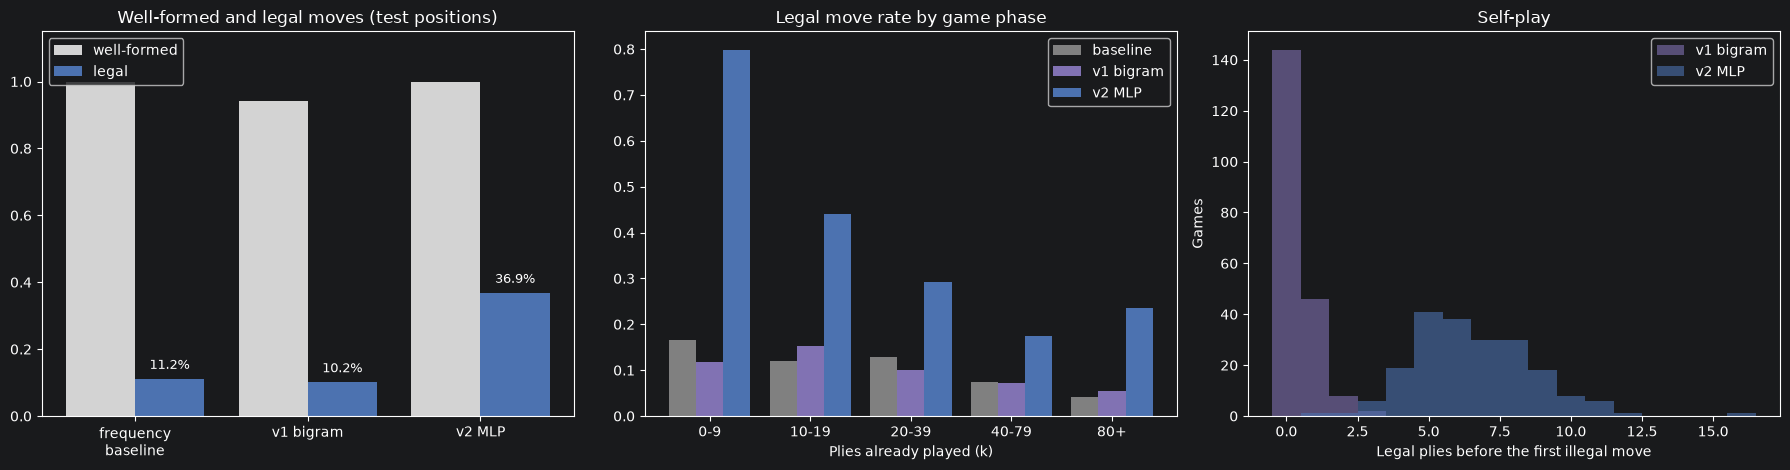

In [9]:
# --- NEXT-MOVE LEGALITY ON THE 1,000 TEST POSITIONS ---

# Fixed seeds.
np.random.seed(0)

# Same for Python's random module.
random.seed(0)

# Start time.
start = time.perf_counter()

# Baseline.
legal_base, wf_base, res_base = evaluate_legality(frequency_baseline)

# Bigram.
legal_bigram, wf_bigram, res_bigram = evaluate_legality(char_model_proposer(bigram_next_char_probs))

# MLP.
legal_mlp, wf_mlp, res_mlp = evaluate_legality(char_model_proposer(mlp_next_char_probs))

# Report.
print(f"Evaluation time: {time.perf_counter() - start:.0f}s\n")

# Header.
print(f"{'model':<22}{'well-formed':>12}{'legal':>8}{'legal / well-formed':>21}")

# One row per model.
for name, wf, legal in [("frequency baseline", wf_base, legal_base), ("v1 bigram", wf_bigram, legal_bigram), ("v2 MLP", wf_mlp, legal_mlp)]:

    # Well-formed rate, legal rate, and the share of well-formed moves that are legal.
    print(f"{name:<22}{wf:>12.1%}{legal:>8.1%}{legal / wf:>21.1%}")

# --- SELF-PLAY ---

# Bigram self-play.
bigram_plies, _ = self_play(bigram_next_char_probs)

# MLP self-play.
mlp_plies, mlp_sequences = self_play(mlp_next_char_probs)

# Summary.
print(f"\nSelf-play (200 games): bigram mean {np.mean(bigram_plies):.2f} plies (max {max(bigram_plies)}) | "
      f"MLP mean {np.mean(mlp_plies):.2f} plies (max {max(mlp_plies)})")

# --- PLOTS ---

# Three panels.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4.8))

# Model names.
names = ["frequency\nbaseline", "v1 bigram", "v2 MLP"]

# Positions of the groups of bars.
x = np.arange(3)

# Well-formed bars (left of each group).
ax1.bar(x - 0.2, [wf_base, wf_bigram, wf_mlp], width=0.4, color="lightgray", label="well-formed")

# Legal bars (right of each group).
bars = ax1.bar(x + 0.2, [legal_base, legal_bigram, legal_mlp], width=0.4, color="#4C72B0", label="legal")

# Write the legal rate on top of the legal bars.
for bar, value in zip(bars, [legal_base, legal_bigram, legal_mlp]):

    # Value label.
    ax1.text(bar.get_x() + bar.get_width() / 2, value + 0.02, f"{value:.1%}", ha="center", va="bottom", fontsize=9)

# Model names on the x-axis.
ax1.set_xticks(x, names)

# Room for the labels.
ax1.set_ylim(0, 1.15)

# Title.
ax1.set_title("Well-formed and legal moves (test positions)")

# Legend.
ax1.legend(loc="upper left")

# Phase chart: three bars per bin.
xp = np.arange(len(PHASE_LABELS))

# Baseline.
ax2.bar(xp - 0.27, rate_by_phase(res_base), width=0.27, color="gray", label="baseline")

# Bigram.
ax2.bar(xp, rate_by_phase(res_bigram), width=0.27, color="#8172B3", label="v1 bigram")

# MLP.
ax2.bar(xp + 0.27, rate_by_phase(res_mlp), width=0.27, color="#4C72B0", label="v2 MLP")

# Bin labels.
ax2.set_xticks(xp, PHASE_LABELS)

# x-axis label.
ax2.set_xlabel("Plies already played (k)")

# Title.
ax2.set_title("Legal move rate by game phase")

# Legend.
ax2.legend()

# Self-play: bins of width 1 up to the longest game.
bins = range(0, max(mlp_plies + bigram_plies) + 2)

# Bigram histogram.
ax3.hist(bigram_plies, bins=bins, alpha=0.6, color="#8172B3", label="v1 bigram", align="left")

# MLP histogram.
ax3.hist(mlp_plies, bins=bins, alpha=0.6, color="#4C72B0", label="v2 MLP", align="left")

# x-axis label.
ax3.set_xlabel("Legal plies before the first illegal move")

# y-axis label.
ax3.set_ylabel("Games")

# Title.
ax3.set_title("Self-play")

# Legend.
ax3.legend()

# Avoid overlapping labels.
plt.tight_layout()

# Render the figure.
plt.show()

## Step 8 — Temperature, examples and the longest self-play game

**Temperature.** A lower temperature makes the model choose its most likely characters more often:

$$
P_\tau(c) \propto P(c)^{1/\tau}
$$

The most likely move is more often legal, so legality should rise as $\tau$ decreases. The price is less variety.
The main comparison between versions always uses $\tau = 1$, the model's honest distribution.

**Examples.** A few positions with the move the MLP proposed, and whether it was well-formed and legal.

**Board.** The final position of the longest legal self-play game.

 temperature  well-formed   legal
         1.0        99.9%   38.6%
         0.8       100.0%   41.5%
         0.5       100.0%   45.8%

Examples (last moves of the context -> MLP move):
  ply  34 | ...Bd4 Qe7 Qa5 b6               -> Nf3      well-formed but illegal
  ply  49 | ...Qg6 Qxd7+ Qf7 Re7            -> Re5      well-formed but illegal
  ply  17 | ...d6 Nf3 d5 cxd5               -> cxd5     legal
  ply   9 | ...Bc5 Nf3 d6 d4                -> Nf6      legal
  ply  34 | ...Ng5 Bc5+ Bf2 Qg3+            -> Kf1      well-formed but illegal
  ply  42 | ...gxf4 gxf4 Kf3 fxe3           -> Kg3      legal
  ply   1 | ...g3                           -> e6       legal
  ply   8 | ...e4 Bb4 a3 Bc5                -> b4       legal
  ply  42 | ...Qf4 Bc6 Nh4 Nh5              -> Bg3      well-formed but illegal
  ply  31 | ...Ng4 Rh1 Kh8 Bd2              -> Re5      well-formed but illegal

Longest legal MLP self-play game (16 plies): e4 c5 c3 Nc6 Nf3 d6 d4 cxd4 Nxd4 Nf6 f4 e6 h4 h5 c4 a6


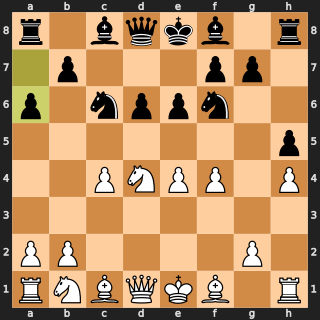

In [10]:
# --- TEMPERATURE SWEEP (legal and well-formed rates of the MLP) ---

# Temperatures to try.
TEMPERATURES = [1.0, 0.8, 0.5]

# Header.
print(f"{'temperature':>12}{'well-formed':>13}{'legal':>8}")

# One evaluation per temperature.
for T in TEMPERATURES:

    # Same seeds for every temperature.
    np.random.seed(0)

    # Evaluate on the 1,000 test positions.
    legal_T, wf_T, _ = evaluate_legality(char_model_proposer(mlp_next_char_probs, temperature=T))

    # Print the row.
    print(f"{T:>12.1f}{wf_T:>13.1%}{legal_T:>8.1%}")

# --- EXAMPLES OF PROPOSED MOVES ---

# Title.
print("\nExamples (last moves of the context -> MLP move):")

# The first 10 test positions.
for (moves, board), (k, legal, san) in zip(test_positions[:10], res_mlp[:10]):

    # Verdict.
    verdict = "legal" if legal else ("well-formed but illegal" if is_well_formed(san) else "malformed")

    # Last 4 moves of the context (or "start" for an empty context).
    tail = " ".join(moves[-4:]) if moves else "(start)"

    # Print the example.
    print(f"  ply {k:3d} | ...{tail:<28} -> {san:<8} {verdict}")

# --- THE LONGEST LEGAL SELF-PLAY GAME ---

# Index of the longest game.
best = int(np.argmax(mlp_plies))

# Its moves.
best_moves = mlp_sequences[best]

# Print them.
print(f"\nLongest legal MLP self-play game ({len(best_moves)} plies):", " ".join(best_moves))

# Replay it.
board = chess.Board()

# One move at a time.
for m in best_moves:

    # Play.
    board.push_san(m)

# Draw the final position with the last move highlighted.
display(SVG(chess.svg.board(board, lastmove=board.peek() if best_moves else None, size=320)))

## Step 9 — Save the results

The v2 numbers are added to the shared file `data`, next to those of v1.

In [11]:
# --- SAVE THE RESULTS OF v2 ---

# Shared results file.
RESULTS_PATH = DATA_DIR / "chessgpt_results.json"

# Load the existing results (written by v1).
results_all = json.loads(RESULTS_PATH.read_text()) if RESULTS_PATH.exists() else {}

# Results of the MLP.
results_all["v2_mlp"] = {
    # Validation bits per character.
    "val_bpc": float(bpc_mlp),
    # Legal move rate at temperature 1.
    "legal_rate": float(legal_mlp),
    # Well-formed rate at temperature 1.
    "well_formed_rate": float(wf_mlp),
    # Average legal plies in self-play.
    "selfplay_mean_plies": float(np.mean(mlp_plies)),
    # Number of parameters.
    "params": int(n_params),
}

# Also store the well-formed rates of the baseline and of the bigram (not computed in v1).
results_all["baseline"]["well_formed_rate"] = float(wf_base)

# Bigram well-formed rate.
results_all["v1_bigram"]["well_formed_rate"] = float(wf_bigram)

# Write the file.
RESULTS_PATH.write_text(json.dumps(results_all, indent=2))

# Show it.
print(json.dumps(results_all, indent=2))

{
  "baseline": {
    "legal_rate": 0.112,
    "well_formed_rate": 1.0
  },
  "v1_bigram": {
    "val_bpc": 2.4304427985659216,
    "legal_rate": 0.102,
    "selfplay_mean_plies": 0.305,
    "well_formed_rate": 0.941
  },
  "v2_mlp": {
    "val_bpc": 1.5581939788328818,
    "legal_rate": 0.369,
    "well_formed_rate": 1.0,
    "selfplay_mean_plies": 6.58,
    "params": 475349
  }
}


### Cosine similarity between embeddings
PCA keeps only two of the 24 dimensions. The **cosine similarity** compares two embeddings using all their dimensions, looking only at the direction of the vectors:

$$
\cos(e_a, e_b) = \frac{e_a \cdot e_b}{\lVert e_a \rVert \, \lVert e_b \rVert} \in [-1, 1]
$$

With the characters ordered by group (files, ranks, pieces, symbols), **blocks** of high similarity along the diagonal would show that the model treats characters of the same group alike.

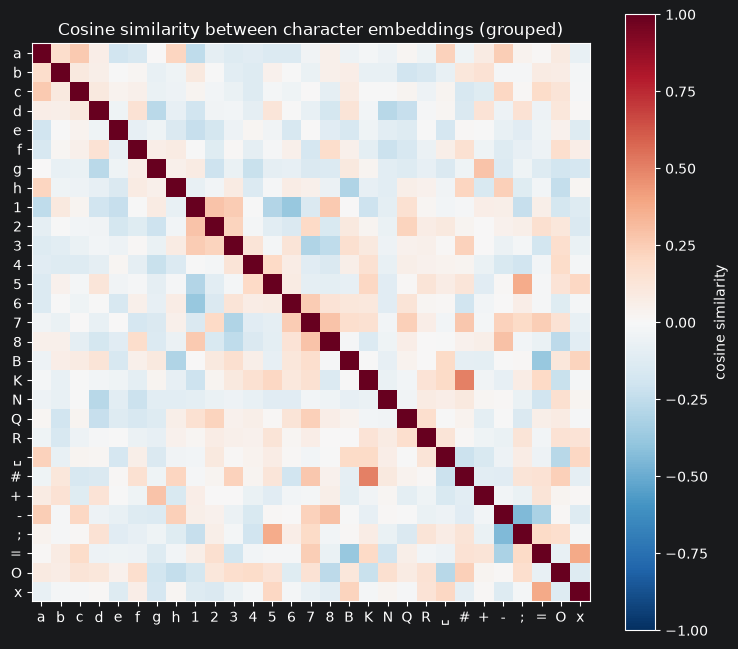

In [12]:
# --- COSINE SIMILARITY BETWEEN EMBEDDINGS, ORDERED BY GROUP ---

# Characters ordered by group: all files, then all ranks, then pieces, then symbols.
order = [c for group in GROUP_COLORS for c in chars if char_group(c) == group]

# Their vocabulary indices.
idx = [stoi[c] for c in order]

# Normalise every embedding to length 1 (divide each row by its norm).
E_norm = E / np.linalg.norm(E, axis=1, keepdims=True)

# Cosine similarity of every pair = dot product of the normalised vectors: a (29 x 29) matrix.
similarity = E_norm[idx] @ E_norm[idx].T

# Square figure.
fig, ax = plt.subplots(figsize=(9, 8))

# Red = similar direction, blue = opposite direction, white = unrelated.
im = ax.imshow(similarity, cmap="RdBu_r", vmin=-1, vmax=1)

# Colour bar.
fig.colorbar(im, ax=ax, label="cosine similarity")

# Tick labels; the space is shown as "␣".
labels = ["␣" if c == " " else c for c in order]

# Column labels.
ax.set_xticks(range(len(order)), labels)

# Row labels.
ax.set_yticks(range(len(order)), labels)

# Title.
ax.set_title("Cosine similarity between character embeddings (grouped)")

# Render the figure.
plt.show()

## Results and conclusions

### Language modelling
| Model | Context | Parameters | Bits/char | Perplexity |
|---|---|---|---|---|
| v1 bigram | 1 char | 841 | 2.430 | 5.39 |
| **v2 MLP** | **16 chars** | **475,349** | **1.558** | **2.94** |

- About **36% fewer bits per character**. Training took 3.5 minutes.
- Train and validation losses are almost identical (1.548 vs 1.557 bpc): **no overfitting**. The limit is the 16-character context, not the amount of training.

### Chess legality (1,000 test positions, temperature 1)
| Model | Well-formed | Legal | Self-play: mean legal plies (max) |
|---|---|---|---|
| Frequency baseline | 100% | 11.2% | — |
| v1 bigram | 94.1% | 10.2% | 0.36 (3) |
| **v2 MLP** | **100%** | **36.5%** | **6.91 (14)** |

- **Every move is now well-formed**, and the legal move rate is **3.3× the baseline**.
- **By game phase:** 78% legal in the first 10 plies, then 42%, 26%, 21% and 23%. In the opening the last 3–4 moves almost determine the position; later, pieces moved earlier fall outside the context window.
- **Temperature:** 39.4% / 43.4% / 47.4% legal at τ = 1.0 / 0.8 / 0.5. With 1,000 positions, sampling noise is about ±1.5 points (the τ = 1 sweep gives 39.4% against 36.5% in the main evaluation).

### What the mistakes reveal
Illegal moves are **plausible chess**: `exd5` recapturing after `cxd5` without a pawn on e4, `exd4` answering `d4`, `Rhe1`.
The model has learned the **typical patterns** of chess games, but not the **state of this particular board**.

### Self-play
The longest game opens with `e4 e5 Nf3 Nc6 Bb5 a6 Ba4 b5 Bb3 d6`, ten plies of correct **Ruy Lopez** theory, followed by four more legal moves.

### Embeddings
The first two principal components explain only 26% of the variance. Three characters with unique roles stand out: `#` (checkmate, ends the game), `=` (promotion, always followed by a piece) and `K` (king moves and castling). The groups of files, ranks and pieces overlap in two dimensions; their structure, if any, lives in the full 24-dimensional space.

### Conclusion and next step
A wider context helps enormously in the opening, and much less afterwards. To play legal moves throughout the game, the model must remember **everything that happened**, not just the last 16 characters.
**v3:** a recurrent network (**LSTM**) that reads the whole game one character at a time and keeps a memory of it in its hidden state.